# Companies Data Analysis

An analysis of company ratings, company types, and headquarters locations.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
raw = pd.read_csv("companies_data.csv")

print("Original shape:", raw.shape)
raw.head()

Original shape: (105000, 7)


,Unnamed: 0,name,rating,reviews,type,hq,employee
0,0,TCS,3.9,NaN,Public,Mumbai + 109 more,10000+ employees
1,1,Accenture,4.0,NaN,Private,Dublin + 89 more,10000+ employees
2,2,ICICI Bank,4.1,NaN,Public,Mumbai + 112 more,10000+ employees
3,3,Cognizant,3.9,NaN,Private,Teaneck + 46 more,10000+ employees
4,4,HDFC Bank,4.0,NaN,Public,Mumbai + 114 more,10000+ employees


In [22]:
raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 105000 entries, 0 to 104999
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Unnamed: 0  105000 non-null  int64  
 1   name        105000 non-null  str    
 2   rating      105000 non-null  float64
 3   reviews     0 non-null       float64
 4   type        105000 non-null  str    
 5   hq          105000 non-null  str    
 6   employee    101500 non-null  str    
dtypes: float64(2), int64(1), str(4)
memory usage: 5.6 MB


In [23]:

raw.isna().sum()


Unnamed: 0         0
name               0
rating             0
reviews       105000
type               0
hq                 0
employee        3500
dtype: int64

In [24]:
raw.describe(include="all")

,Unnamed: 0,name,rating,reviews,type,hq,employee
count,105000.000000,105000,105000.000000,0.0,105000,105000,101500
unique,NaN,30,NaN,NaN,4,26,1
top,NaN,TCS,NaN,NaN,Public,Mumbai + 114 more,10000+ employees
freq,NaN,3500,NaN,NaN,66500,10500,101500
mean,13928.071429,NaN,3.996667,NaN,NaN,NaN,NaN
std,8593.761929,NaN,0.257532,NaN,NaN,NaN,NaN
min,0.000000,NaN,3.300000,NaN,NaN,NaN,NaN
25%,6562.000000,NaN,3.900000,NaN,NaN,NaN,NaN
50%,13124.500000,NaN,4.000000,NaN,NaN,NaN,NaN
75%,21249.250000,NaN,4.100000,NaN,NaN,NaN,NaN


In [25]:
df = raw.drop(columns=["Unnamed: 0"], errors="ignore")

# Fix the malformed Concentrix row in the source CSV.
df.loc[df["name"] == "Concentrix Daksh Service...", ["type", "hq", "employee"]] = [
    "Private",
    "New Delhi + 36 more",
    "10000+ employees",
]

df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned shape:", df.shape)
df.isna().sum()

Cleaned shape: (30, 6)


name         0
rating       0
reviews     30
type         0
hq           0
employee     0
dtype: int64

In [26]:
raw.shape

(105000, 7)

In [27]:
if "reviews" in df.columns and df["reviews"].isna().all():
    df = df.drop(columns="reviews")

df["employee"] = df["employee"].fillna("Unknown")

In [28]:
ratings = df.sort_values("rating", ascending=False)

ratings[["name", "rating"]].head(10)

,name,rating
27,Indian Army,4.7
17,Vodafone,4.3
28,Mahindra & Mahindra,4.3
19,Bharti Airtel,4.2
22,Reliance,4.2
26,Samsung,4.2
21,Amazon,4.2
24,Bajaj Finserv,4.1
2,ICICI Bank,4.1
6,L&T,4.1


In [29]:
ratings[["name", "rating"]].tail(10)


,name,rating
3,Cognizant,3.9
0,TCS,3.9
23,Hinduja Global Solutions,3.9
5,Infosys,3.9
20,Kotak Mahindra Bank,3.8
15,Wipro,3.8
9,HCL Technologies,3.7
25,IndusInd Bank,3.6
8,Tech Mahindra,3.5
7,Capgemini,3.3


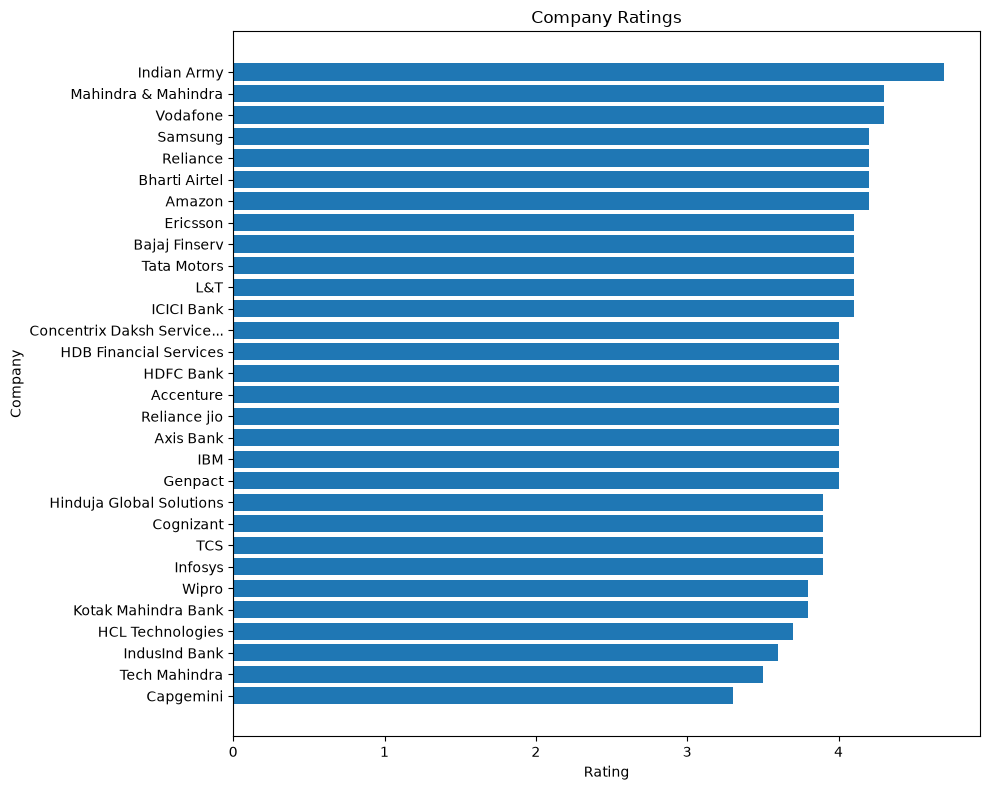

In [30]:
chart_data = df.sort_values("rating", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(chart_data["name"], chart_data["rating"])
plt.xlabel("Rating")
plt.ylabel("Company")
plt.title("Company Ratings")
plt.tight_layout()
plt.show()

In [31]:
comparison = df[df["type"].isin(["Public", "Private"])]

comparison.groupby("type")["rating"].mean().sort_values(ascending=False)

type
Public     3.973684
Private    3.970000
Name: rating, dtype: float64

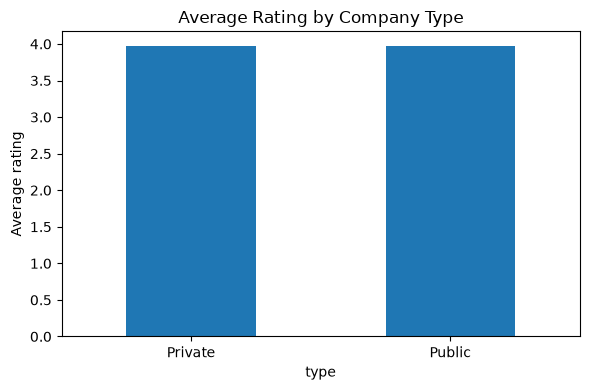

In [32]:
type_ratings = comparison.groupby("type")["rating"].mean()

type_ratings.plot(kind="bar", figsize=(6, 4))
plt.ylabel("Average rating")
plt.title("Average Rating by Company Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Rating Distribution

This section looks at how company ratings are distributed. It helps show whether ratings tend to cluster around a particular range and whether unusually high or low ratings are present.

count    30.000000
mean      3.996667
std       0.261934
min       3.300000
25%       3.900000
50%       4.000000
75%       4.100000
max       4.700000
Name: rating, dtype: float64
rating
3.3    1
3.5    1
3.6    1
3.7    1
3.8    2
3.9    4
4.0    8
4.1    5
4.2    4
4.3    2
4.7    1
Name: count, dtype: int64


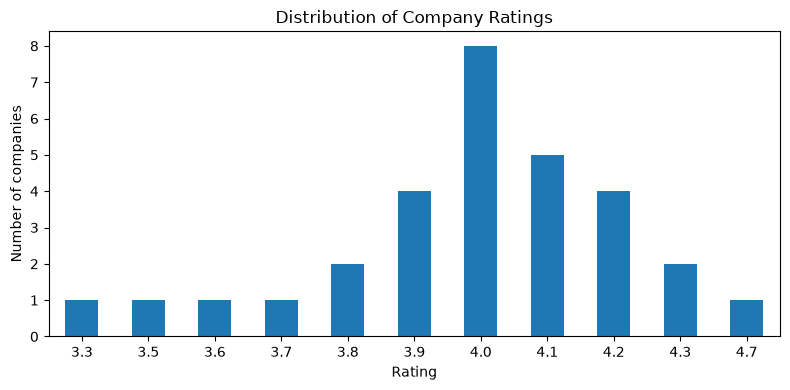

In [33]:
print(df["rating"].describe())

rating_counts = df["rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", figsize=(8, 4))
plt.xlabel("Rating")
plt.ylabel("Number of companies")
plt.title("Distribution of Company Ratings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Highest- and Lowest-Rated Companies

Here I compare the companies with the highest and lowest ratings in the cleaned dataset.

In [34]:
print("Top-rated companies:")
display(df.nlargest(10, "rating")[["name", "rating", "type", "hq"]])

print("Lowest-rated companies:")
display(df.nsmallest(10, "rating")[["name", "rating", "type", "hq"]])

Top-rated companies:


,name,rating,type,hq
27,Indian Army,4.7,Govt agency,New Delhi + 114 more
17,Vodafone,4.3,Public,Berkshire + 115 more
28,Mahindra & Mahindra,4.3,Public,Mumbai + 116 more
19,Bharti Airtel,4.2,Public,New Delhi + 114 more
21,Amazon,4.2,Private,Washington + 113 more
22,Reliance,4.2,Public,Mumbai + 114 more
26,Samsung,4.2,Private,Seoul + 117 more
2,ICICI Bank,4.1,Public,Mumbai + 112 more
6,L&T,4.1,Public,Mumbai + 115 more
10,Tata Motors,4.1,Public,Pune + 115 more


Lowest-rated companies:


,name,rating,type,hq
7,Capgemini,3.3,Private,Paris + 44 more
8,Tech Mahindra,3.5,Public,Pune + 109 more
25,IndusInd Bank,3.6,Public,Mumbai + 113 more
9,HCL Technologies,3.7,Public,Noida + 107 more
15,Wipro,3.8,Public,Bangalore + 114 more
20,Kotak Mahindra Bank,3.8,Public,Mumbai + 114 more
0,TCS,3.9,Public,Mumbai + 109 more
3,Cognizant,3.9,Private,Teaneck + 46 more
5,Infosys,3.9,Public,Bangalore + 67 more
23,Hinduja Global Solutions,3.9,Public,Bangalore + 76 more


## Ratings by Company Type

I compare the average and median ratings of public and private companies. Other values in the company-type column are excluded because they may be data-entry or scraping errors.

,count,mean,median
type,,,
Private,10,3.970000,4.0
Public,19,3.973684,4.0


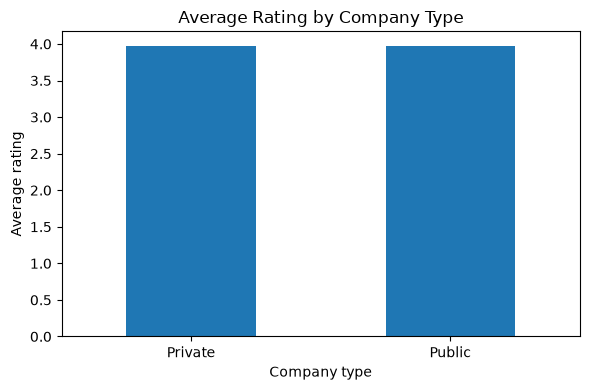

In [35]:
type_comparison = df[df["type"].isin(["Public", "Private"])]

type_summary = type_comparison.groupby("type")["rating"].agg(
    ["count", "mean", "median"]
)

display(type_summary)

type_summary["mean"].plot(kind="bar", figsize=(6, 4))
plt.xlabel("Company type")
plt.ylabel("Average rating")
plt.title("Average Rating by Company Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
df.to_csv("clean_companies_data.csv", index=False)

## Headquarters Locations

I extract the first listed city from the headquarters field and count how often each city appears. This is only a basic location analysis because the dataset does not provide complete headquarters information for every location.

hq_city
Mumbai         9
Bangalore      3
Pune           3
New Delhi      3
New York       2
Dublin         1
Teaneck        1
Paris          1
Noida          1
Navi Mumbai    1
Berkshire      1
Ahmedabad      1
Washington     1
Seoul          1
Stockholm      1
Name: count, dtype: int64

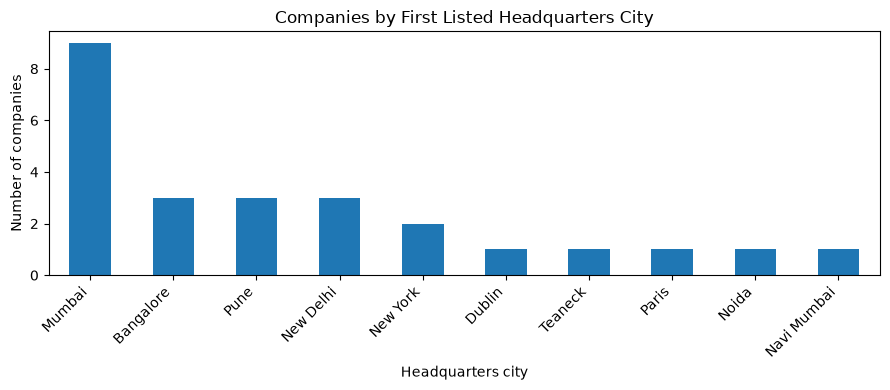

In [36]:
valid_hq = df[df["hq"].str.contains(r"\+\s*\d+\s+more$", na=False)].copy()
valid_hq["hq_city"] = valid_hq["hq"].str.split("+", n=1).str[0].str.strip()

city_counts = valid_hq["hq_city"].value_counts()
display(city_counts)

city_counts.head(10).plot(kind="bar", figsize=(9, 4))
plt.xlabel("Headquarters city")
plt.ylabel("Number of companies")
plt.title("Companies by First Listed Headquarters City")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Data Quality Findings

During data preparation, I found repeated records, an empty reviews column, missing employee information, and unusual values in some company-type entries. These issues limit what can be concluded from the dataset.

The employee information is also not very useful for comparing companies if nearly every value belongs to the same category.

## Questions This Project Explores

1. What is the overall range and distribution of company ratings?
2. Which companies have the highest and lowest ratings?
3. How do ratings compare between public and private companies in this dataset?
4. Which headquarters cities appear most often?
5. What data-quality issues could affect the analysis?

rating_band
Below 3.5            1
3.5 to below 4.0     9
4.0 and above       20
Name: count, dtype: int64

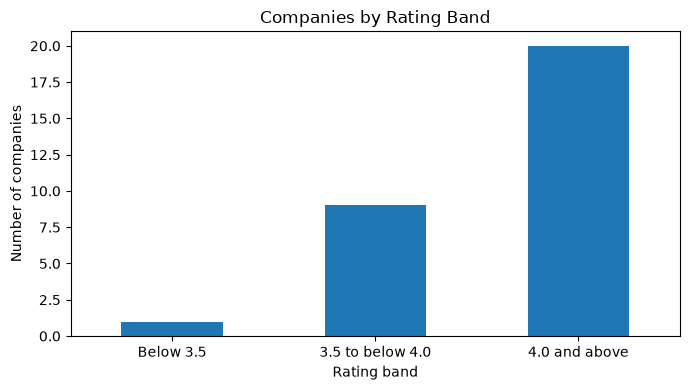

In [37]:
bins = [0, 3.5, 4.0, 5.0]
labels = ["Below 3.5", "3.5 to below 4.0", "4.0 and above"]

df["rating_band"] = pd.cut(
    df["rating"],
    bins=bins,
    labels=labels,
    right=False
)

display(df["rating_band"].value_counts().sort_index())

df["rating_band"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)
plt.xlabel("Rating band")
plt.ylabel("Number of companies")
plt.title("Companies by Rating Band")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Exploring Company Ratings

I will summarize the company ratings and identify which companies have the highest and lowest ratings. This helps me understand the range of ratings in the cleaned dataset.

In [38]:
print("Number of companies:", len(df))
print("Average rating:", round(df["rating"].mean(), 2))
print("Median rating:", round(df["rating"].median(), 2))
print("Lowest rating:", df["rating"].min())
print("Highest rating:", df["rating"].max())

print("\nTop-rated companies:")
display(df.nlargest(5, "rating")[["name", "rating"]])

print("\nLowest-rated companies:")
display(df.nsmallest(5, "rating")[["name", "rating"]])

Number of companies: 30
Average rating: 4.0
Median rating: 4.0
Lowest rating: 3.3
Highest rating: 4.7

Top-rated companies:


,name,rating
27,Indian Army,4.7
17,Vodafone,4.3
28,Mahindra & Mahindra,4.3
19,Bharti Airtel,4.2
21,Amazon,4.2



Lowest-rated companies:


,name,rating
7,Capgemini,3.3
8,Tech Mahindra,3.5
25,IndusInd Bank,3.6
9,HCL Technologies,3.7
15,Wipro,3.8


## Conclusion

This project explored company ratings and profile information using Pandas and Matplotlib. Although the original dataset contains 105,000 rows, many are repeated. After correcting the malformed Concentrix record and removing exact duplicate records, the analysis contains 30 distinct companies.

The average company rating is approximately **4.00**, and the median is **4.0**. Ratings range from **3.3 to 4.7**, with most companies rated near 4.0. This suggests that ratings in this dataset are generally clustered around the same level, rather than spread evenly across the full scale.

The data also has limitations. The reviews column is empty, and employee information has little variation. The source CSV also contains a malformed Concentrix row, which was corrected in this analysis. Most importantly, the dataset does not include sales or revenue figures, so this project cannot make sales or revenue conclusions.

Overall, the project demonstrates how to inspect, clean, summarize, and visualize company data. Its findings describe only the 30 distinct companies in this dataset and should not be treated as representative of all companies.